In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
import utils.data_api as api

In [11]:
sudan_s_df = api.get_data_from_power_api(
    longitude = 30.0,
    latitude = 12.0,
    start_date = '20240615',
    end_date = '20240630',
    export_to_csv = False
)

In [12]:
# --- Grouping by hour ---
grouped_sudan_s_df = (
    sudan_s_df.groupby('hour')
    .agg(
        solar_radiation_mean=('solar_radiation', 'mean'),
        solar_radiation_std=('solar_radiation', 'std'),
        temp_mean=('temp', 'mean'),
        temp_std=('temp', 'std')
    )
    .reset_index()
)

# Filter for hour between 5 and 10
filtered_grouped = grouped_sudan_s_df[
    (grouped_sudan_s_df['hour'] >= 5) &
    (grouped_sudan_s_df['hour'] <= 10)
]

# Prepare data for regression
X = filtered_grouped['solar_radiation_mean'].values.reshape(-1, 1)
y = filtered_grouped['temp_mean'].values
sigma_y = filtered_grouped['temp_std'].values  # standard deviation of temp

# Fit linear regression on means
model = LinearRegression()
model.fit(X, y)

# Prediction line
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = model.predict(x_line)

# Predictions for χ² calculation
y_pred = model.predict(X)

# χ² with std as weights
chi_squared = np.sum(((y - y_pred) / sigma_y) ** 2)
n = len(y)
p = 2  # slope + intercept
chi_squared_red = chi_squared / (n - p)

# R²
r_squared = model.score(X, y)

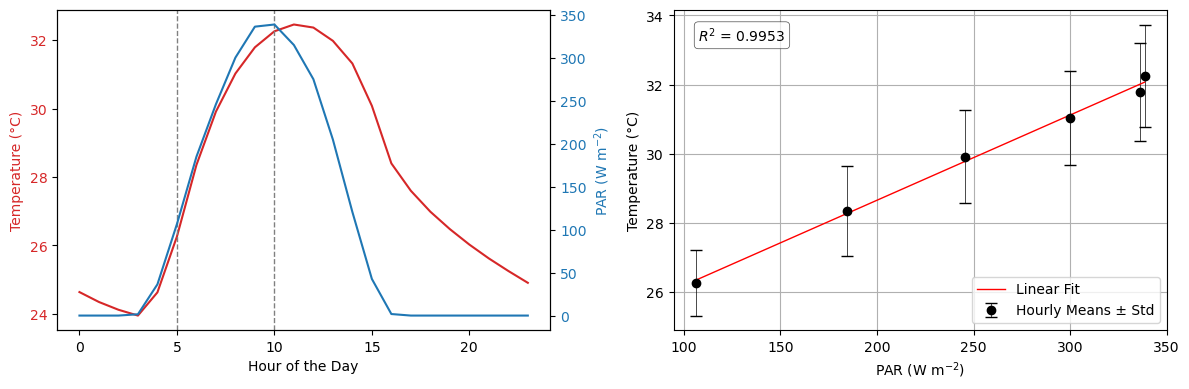

In [13]:
fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(12, 4))

# --- First subplot: Temperature & Radiation vs Hour ---
ax1.set_xlabel('Hour of the Day')
ax1.set_ylabel('Temperature (°C)', color='tab:red')
ax1.plot(grouped_sudan_s_df['hour'], grouped_sudan_s_df['temp_mean'] - 273.15,
         color='tab:red', label='Temperature')
ax1.axvline(x=5, color='gray', linestyle='--', linewidth=1)
ax1.axvline(x=10, color='gray', linestyle='--', linewidth=1)
ax1.tick_params(axis='y', labelcolor='tab:red')

# Twin y-axis for radiation
ax1_radiation = ax1.twinx()
ax1_radiation.set_ylabel('PAR (W m$^{-2}$)', color='tab:blue')
ax1_radiation.plot(grouped_sudan_s_df['hour'], grouped_sudan_s_df['solar_radiation_mean'],
                   color='tab:blue', label='Radiation')
ax1_radiation.tick_params(axis='y', labelcolor='tab:blue')

# --- Second subplot: Scatter + Linear Fit ---
ax3.errorbar(X.flatten(), y - 273.15, yerr=sigma_y, fmt='o',
             capsize=4, label='Hourly Means ± Std', color='black', ecolor='black', elinewidth=0.5)
ax3.plot(x_line, y_line - 273.15, color='red', linewidth=1, label='Linear Fit')

ax3.set_xlabel('PAR (W m$^{-2}$)')
ax3.set_ylabel('Temperature (°C)')
ax3.legend()
ax3.grid(True)

# Add R² in the second subplot
ax3.text(0.05, 0.95,
         f"$R^2$ = {r_squared:.4f}",
         transform=ax3.transAxes,
         fontsize=10, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.7, linewidth=0.5))

fig.tight_layout()

plt.savefig('plots/sudan_temperature_fit.png', dpi=300, bbox_inches='tight')

In [ ]:
sudan_w_df = api.get_data_from_power_api(
    longitude = 30.0,
    latitude = 12.0,
    start_date = '20231201',
    end_date = '20231231',
    export_to_csv = False
)



In [6]:
# Grouping the data by hour and calculating the mean
grouped_sudan_w_df = sudan_w_df.groupby('hour').mean().reset_index()

# Filter for hour between 5 and 10 and drop rows with missing values
filtered_sudan_w_df = (
    sudan_w_df[(sudan_w_df['hour'] >= 5) 
               & (sudan_w_df['hour'] <= 10)][['solar_radiation', 'temp']]
    .dropna()
)

# Prepare features and target for regression
X = filtered_sudan_w_df['solar_radiation'].values.reshape(-1, 1)
y = filtered_sudan_w_df['temp'].values

# Fit linear regression model
model = LinearRegression()
model.fit(X, y)

# Generate prediction line
sudan_w_x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
sudan_w_y_line = model.predict(sudan_w_x_line)

# Output regression results
print(f"Intercept (Sudan Dec): {model.intercept_}")
print(f"Slope (Sudan Dec): {model.coef_[0]}")
print(f"R² (Sudan Dec): {model.score(X, y):.4f}")

Intercept (Sudan Dec): 277.9353489903067
Slope (Sudan Dec): 0.0364441909867683
R² (Sudan Dec): 0.6735


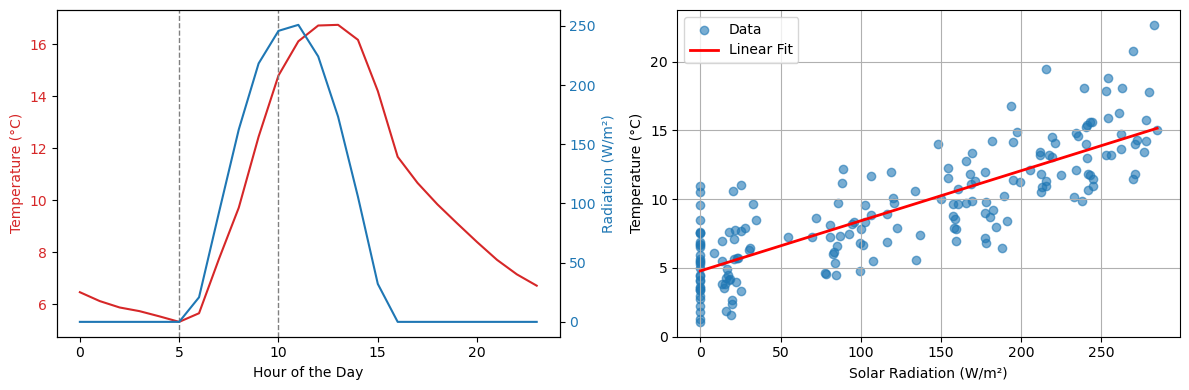

In [7]:
fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(12, 4))

# --- First subplot: Temperature & Radiation vs Hour ---
ax1.set_xlabel('Hour of the Day')
ax1.set_ylabel('Temperature (°C)', color='tab:red')
ax1.plot(grouped_sudan_w_df['hour'], grouped_sudan_w_df['temp'] - 273.15,
         color='tab:red', label='Temperature')
ax1.axvline(x=5, color='gray', linestyle='--', linewidth=1)
ax1.axvline(x=10, color='gray', linestyle='--', linewidth=1)
ax1.tick_params(axis='y', labelcolor='tab:red')

ax2 = ax1.twinx()
ax2.set_ylabel('Radiation (W/m²)', color='tab:blue')
ax2.plot(grouped_sudan_w_df['hour'], grouped_sudan_w_df['solar_radiation'],
         color='tab:blue', label='Radiation')
ax2.tick_params(axis='y', labelcolor='tab:blue')

# --- Second subplot: Scatter + Linear Fit ---
ax3.scatter(filtered_sudan_w_df['solar_radiation'],
            filtered_sudan_w_df['temp'] - 273.15,
            alpha=0.6, label='Data')
ax3.plot(sudan_w_x_line, sudan_w_y_line - 273.15,
         color='red', linewidth=2, label='Linear Fit')
ax3.set_xlabel('Solar Radiation (W/m²)')
ax3.set_ylabel('Temperature (°C)')
ax3.legend()
ax3.grid(True)

fig.tight_layout()

In [8]:
germany_s_df = api.get_data_from_power_api(
    longitude = 8.0,
    latitude = 51.0,
    start_date = '20240615',
    end_date = '20240630',
    export_to_csv = False
)

In [9]:
# Grouping the data by hour and calculating the mean
grouped_germany_s_df = germany_s_df.groupby('hour').mean().reset_index()

# Filter for hour between 5 and 10 and drop rows with missing values
filtered_germany_s_df = (
    germany_s_df[(germany_s_df['hour'] >= 5) 
               & (germany_s_df['hour'] <= 10)][['solar_radiation', 'temp']]
    .dropna()
)

# Prepare features and target for regression
X = filtered_germany_s_df['solar_radiation'].values.reshape(-1, 1)
y = filtered_germany_s_df['temp'].values

# Fit linear regression model
model = LinearRegression()
model.fit(X, y)

# Generate prediction line
germany_s_x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
germany_s_y_line = model.predict(germany_s_x_line)

# Predictions for your actual X values
y_pred = model.predict(X)

# Residuals
residuals = y - y_pred

# If no uncertainties are known, assume sigma = 1
chi_squared = np.sum((residuals)**2)

# Reduced chi-squared
n = len(y)
p = 2  # slope + intercept
chi_squared_red = chi_squared / (n - p)

In [10]:
# --- Grouping by hour ---
grouped_germany_s_df = (
    germany_s_df.groupby('hour')
    .agg(
        solar_radiation_mean=('solar_radiation', 'mean'),
        solar_radiation_std=('solar_radiation', 'std'),
        temp_mean=('temp', 'mean'),
        temp_std=('temp', 'std')
    )
    .reset_index()
)

# Filter for hour between 5 and 10
filtered_grouped = grouped_germany_s_df[
    (grouped_germany_s_df['hour'] >= 5) &
    (grouped_germany_s_df['hour'] <= 10)
]

# Prepare data for regression
X = filtered_grouped['solar_radiation_mean'].values.reshape(-1, 1)
y = filtered_grouped['temp_mean'].values
sigma_y = filtered_grouped['temp_std'].values  # standard deviation of temp

# Fit linear regression on means
model = LinearRegression()
model.fit(X, y)

# Prediction line
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = model.predict(x_line)

# Predictions for χ² calculation
y_pred = model.predict(X)

# χ² with std as weights
chi_squared = np.sum(((y - y_pred) / sigma_y) ** 2)
n = len(y)
p = 2  # slope + intercept
chi_squared_red = chi_squared / (n - p)

# R²
r_squared = model.score(X, y)

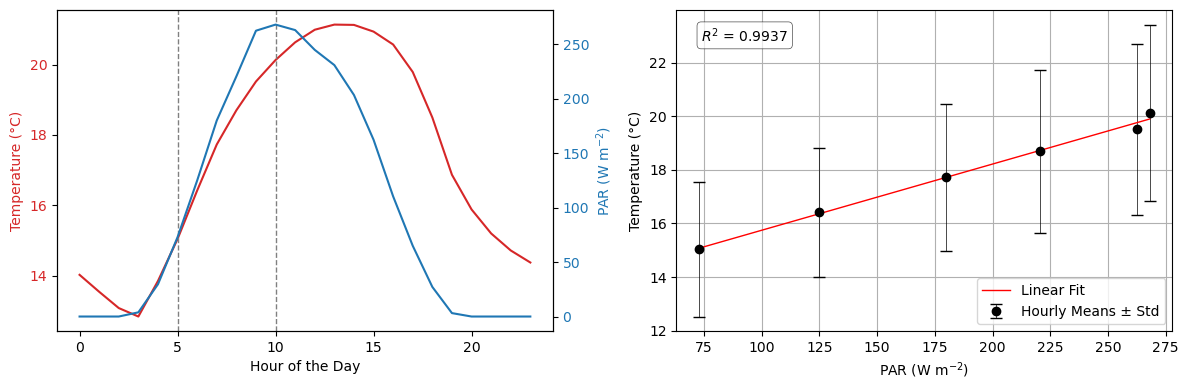

In [11]:
fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(12, 4))

# --- First subplot: Temperature & Radiation vs Hour ---
ax1.set_xlabel('Hour of the Day')
ax1.set_ylabel('Temperature (°C)', color='tab:red')
ax1.plot(grouped_germany_s_df['hour'], grouped_germany_s_df['temp_mean'] - 273.15,
         color='tab:red', label='Temperature')
ax1.axvline(x=5, color='gray', linestyle='--', linewidth=1)
ax1.axvline(x=10, color='gray', linestyle='--', linewidth=1)
ax1.tick_params(axis='y', labelcolor='tab:red')

# Twin y-axis for radiation
ax1_radiation = ax1.twinx()
ax1_radiation.set_ylabel('PAR (W m$^{-2}$)', color='tab:blue')
ax1_radiation.plot(grouped_germany_s_df['hour'], grouped_germany_s_df['solar_radiation_mean'],
                   color='tab:blue', label='Radiation')
ax1_radiation.tick_params(axis='y', labelcolor='tab:blue')

# --- Second subplot: Scatter + Linear Fit ---
ax3.errorbar(X.flatten(), y - 273.15, yerr=sigma_y, fmt='o',
             capsize=4, label='Hourly Means ± Std', color='black', ecolor='black', elinewidth=0.5)
ax3.plot(x_line, y_line - 273.15, color='red', linewidth=1, label='Linear Fit')

ax3.set_xlabel('PAR (W m$^{-2}$)')
ax3.set_ylabel('Temperature (°C)')
ax3.legend()
ax3.grid(True)

# Add R² in the second subplot
ax3.text(0.05, 0.95,
         f"$R^2$ = {r_squared:.4f}",
         transform=ax3.transAxes,
         fontsize=10, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.7, linewidth=0.5))

fig.tight_layout()

In [12]:
germany_s_df = api.get_data_from_power_api(
    longitude = 8.0,
    latitude = 51.0,
    start_date = '20240615',
    end_date = '20240615',
    export_to_csv = False
)

In [13]:
# Filter for hour between 5 and 10
filtered_df = germany_s_df[
    (germany_s_df['hour'] >= 5) &
    (germany_s_df['hour'] <= 10)
]

# Prepare data for regression
X = filtered_df['solar_radiation'].values.reshape(-1, 1)
y = filtered_df['temp'].values

# Fit linear regression on means
model = LinearRegression()
model.fit(X, y)

# Prediction line
x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = model.predict(x_line)

# R²
r_squared = model.score(X, y)

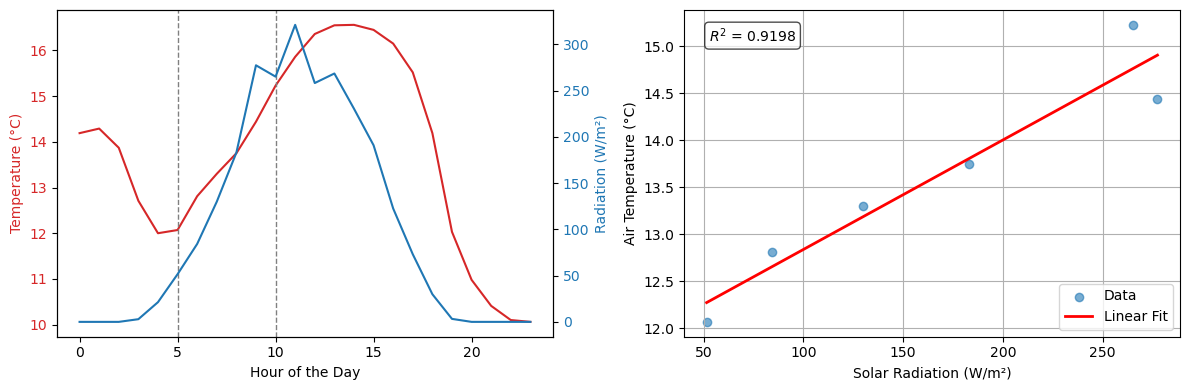

In [14]:
fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(12, 4))

# --- First subplot: Temperature & Radiation vs Hour ---
ax1.set_xlabel('Hour of the Day')
ax1.set_ylabel('Temperature (°C)', color='tab:red')
ax1.plot(germany_s_df['hour'], germany_s_df['temp'] - 273.15,
         color='tab:red', label='Temperature')
ax1.axvline(x=5, color='gray', linestyle='--', linewidth=1)
ax1.axvline(x=10, color='gray', linestyle='--', linewidth=1)
ax1.tick_params(axis='y', labelcolor='tab:red')

# Twin y-axis for radiation
ax1_radiation = ax1.twinx()
ax1_radiation.set_ylabel('Radiation (W/m²)', color='tab:blue')
ax1_radiation.plot(germany_s_df['hour'], germany_s_df['solar_radiation'],
                   color='tab:blue', label='Radiation')
ax1_radiation.tick_params(axis='y', labelcolor='tab:blue')

# --- Second subplot: Scatter + Linear Fit ---
ax3.scatter(filtered_df['solar_radiation'],
            filtered_df['temp'] - 273.15,
            alpha=0.6, label='Data')
ax3.plot(x_line, y_line - 273.15, color='red', linewidth=2, label='Linear Fit')

ax3.set_xlabel('Solar Radiation (W/m²)')
ax3.set_ylabel('Air Temperature (°C)')
ax3.legend()
ax3.grid(True)

# Add R² in the second subplot
ax3.text(0.05, 0.95,
         f"$R^2$ = {r_squared:.4f}",
         transform=ax3.transAxes,
         fontsize=10, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

fig.tight_layout()